# Predicting How Hard an English Text Is (OneStopEnglish)
**Nhóm 07 – lớp 62FIT4MLA – CLC01.** Notebook dự án sau góp ý giữa kỳ của thầy Khánh.

Notebook làm theo thứ tự góp ý của thầy:
1. Tải dữ liệu và trích đặc trưng (3 đặc trưng gốc + 7 đặc trưng mở rộng).
2. So sánh **chia ngẫu nhiên** và **chia theo bài gốc** (5 fold × 5 lần lặp).
3. Baseline: Flesch-Kincaid, Logistic Regression, Linear SVM, cây nông.
4. Metric: accuracy, QWK, tỷ lệ lỗi hai mức, ma trận nhầm lẫn.
5. Đặc trưng nào phân biệt ba mức; văn bản nào khó phân biệt nhất.
6. Kiểm tra thêm bằng mô hình TF-IDF.
7. Thử trên văn bản ngoài bộ dữ liệu (nhóm tự điền).

Dữ liệu: OneStopEnglish (Vajjala & Lučić, 2018), licence CC BY-SA 4.0.

## 0. Cài đặt và tải dữ liệu

In [1]:
import importlib, subprocess, sys, os
def ensure(pkg, mod=None):
    try: importlib.import_module(mod or pkg)
    except ImportError:
        subprocess.run([sys.executable,'-m','pip','install','-q',pkg,'--break-system-packages'],check=False)
ensure('wordfreq'); ensure('spacy')
try:
    import spacy; spacy.load('en_core_web_sm')
except Exception:
    subprocess.run([sys.executable,'-m','spacy','download','en_core_web_sm'],check=False,
                   env={**os.environ,'PIP_BREAK_SYSTEM_PACKAGES':'1'})

DATA_REPO = 'OneStopEnglishCorpus'
if not os.path.exists(DATA_REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/nishkalavallabhi/OneStopEnglishCorpus.git'],check=True)
BASE = f'{DATA_REPO}/Texts-SeparatedByReadingLevel'
print(os.listdir(BASE))

['Adv-Txt', 'Ele-Txt', 'Int-Txt']


In [2]:
import re, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt, spacy
from wordfreq import zipf_frequency
from scipy.stats import kruskal
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

LEVELS = {'Elementary': ('Ele-Txt','-ele.txt'), 'Intermediate': ('Int-Txt','-int.txt'), 'Advanced': ('Adv-Txt','-adv.txt')}
ORDER = {'Elementary':0, 'Intermediate':1, 'Advanced':2}
rows = []
for lvl,(d,suf) in LEVELS.items():
    for f in sorted(os.listdir(f'{BASE}/{d}')):
        if f.endswith('.txt'):
            text = open(f'{BASE}/{d}/{f}', encoding='utf-8', errors='ignore').read()
            rows.append(dict(article=f[:-len(suf)], level=lvl, text=text))
data = pd.DataFrame(rows)
print(data.groupby('level').size())
print('Số bài gốc:', data.article.nunique(), '| tổng văn bản:', len(data))
assert data.article.nunique() == 189, 'ID bài gốc sai: mỗi bài phải có đúng 3 phiên bản'

level
Advanced        189
Elementary      189
Intermediate    189
dtype: int64
Số bài gốc: 189 | tổng văn bản: 567


## 1. Trích đặc trưng
- **3 đặc trưng gốc:** độ dài câu, độ dài từ, tỷ lệ từ hiếm (Zipf < 3).
- **7 đặc trưng mở rộng:** Zipf trung bình, tỷ lệ từ ngoài nhóm tần suất cao (Zipf < 4), Zipf phân vị 10, số từ mỗi mệnh đề, số mệnh đề phụ mỗi câu, tỷ lệ từ dài từ 7 chữ, type-token ratio.
- Flesch-Kincaid: số âm tiết đếm xấp xỉ theo nhóm nguyên âm.
- Chưa có Academic Word List nên tỷ lệ từ dài từ 7 chữ chỉ là **chỉ báo thay thế**; nhóm nên thay bằng AWL thật.
- Độ dài văn bản (số từ) được tính để mô tả nhưng **không đưa vào mô hình**, tránh mô hình chỉ học độ dài.

In [3]:
nlp = spacy.load('en_core_web_sm')

def syllables(w):
    w = w.lower(); n = len(re.findall(r'[aeiouy]+', w))
    if w.endswith('e') and n > 1: n -= 1
    return max(n, 1)

def extract(text):
    doc = nlp(re.sub(r'\s+', ' ', text))
    sents = list(doc.sents)
    words = [w for w in doc if w.is_alpha]
    wl = [len(w.text) for w in words]
    z = np.array([zipf_frequency(w.lower_, 'en') for w in words])
    n_clause = sum(1 for w in doc if w.pos_ in ('VERB','AUX') and w.dep_ not in ('aux','auxpass','cop')) or 1
    n_sub = sum(1 for w in doc if w.dep_ in ('advcl','ccomp','acl','relcl','csubj'))
    sent_len = len(words)/len(sents)
    syl = np.mean([syllables(w.text) for w in words])
    return dict(
        sent_len=sent_len, word_len=np.mean(wl), rare_ratio=np.mean(z < 3.0),
        mean_zipf=z.mean(), ratio_outside_top5k=np.mean(z < 4.0), p10_zipf=np.percentile(z, 10),
        words_per_clause=len(words)/n_clause, sub_per_sent=n_sub/len(sents),
        long_word_ratio=np.mean(np.array(wl) >= 7), ttr=len({w.lower_ for w in words})/len(words),
        fk=0.39*sent_len + 11.8*syl - 15.59, n_words=len(words))

CACHE = 'features.csv'
if os.path.exists(CACHE):
    feats = pd.read_csv(CACHE)
else:
    feats = pd.DataFrame([extract(t) for t in data.text]); feats.to_csv(CACHE, index=False)
df = pd.concat([data.drop(columns='text'), feats], axis=1)
y = df.level.map(ORDER).values
groups = df.article.values
S3  = ['sent_len','word_len','rare_ratio']
EXP = S3 + ['mean_zipf','ratio_outside_top5k','p10_zipf','words_per_clause','sub_per_sent','long_word_ratio','ttr']
df.groupby('level')[EXP+['fk','n_words']].mean().loc[list(ORDER)].round(3).T

level,Elementary,Intermediate,Advanced
sent_len,16.643,19.560,21.875
word_len,4.541,4.652,4.730
rare_ratio,0.023,0.030,0.029
mean_zipf,5.826,5.750,5.733
ratio_outside_top5k,0.076,0.094,0.103
p10_zipf,4.203,4.044,3.979
words_per_clause,6.411,6.676,6.619
sub_per_sent,1.060,1.233,1.438
long_word_ratio,0.197,0.220,0.234
ttr,0.456,0.467,0.466


## 2. So sánh chia ngẫu nhiên và chia theo bài gốc
- **Chia ngẫu nhiên:** `StratifiedKFold`; ba phiên bản của một bài có thể nằm hai phía train/test.
- **Chia theo bài gốc:** `StratifiedGroupKFold` với ID bài làm nhóm; ba phiên bản luôn nằm cùng một phía.
- Mỗi cấu hình: 5 fold × 5 lần lặp = 25 lần đánh giá, cùng mô hình và siêu tham số cố định (chưa tune).
- Metric: accuracy, Macro F1, QWK, tỷ lệ lỗi hai mức (Elementary ↔ Advanced).

In [4]:
feature_sets = {'Flesch-Kincaid (1 số)': ['fk'], '3 đặc trưng gốc': S3, 'Mở rộng (10)': EXP}
models = {
    'LR':       lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)),
    'SVM':      lambda: make_pipeline(StandardScaler(), LinearSVC(C=1, max_iter=20000)),
    'Cây nông': lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=0)}

def splitter(kind, X, rep):
    if kind == 'random':
        return StratifiedKFold(5, shuffle=True, random_state=rep).split(X, y)
    return StratifiedGroupKFold(5, shuffle=True, random_state=rep).split(X, y, groups)

def evaluate(kind, X, make_model, reps=5):
    scores, cm = [], np.zeros((3,3), int)
    for rep in range(reps):
        for tr, te in splitter(kind, X, rep):
            p = make_model().fit(X[tr], y[tr]).predict(X[te])
            scores.append((accuracy_score(y[te], p), f1_score(y[te], p, average='macro'),
                           cohen_kappa_score(y[te], p, weights='quadratic'), np.mean(np.abs(p - y[te]) == 2)))
            cm += confusion_matrix(y[te], p, labels=[0,1,2])
    s = np.array(scores)
    return s.mean(0), s.std(0), cm

records, matrices = [], {}
for fs_name, cols in feature_sets.items():
    X = df[cols].values
    for m_name, mk in models.items():
        for kind in ['group', 'random']:
            mean, sd, cm = evaluate(kind, X, mk)
            records.append(dict(features=fs_name, model=m_name, split=kind, accuracy=mean[0], acc_sd=sd[0],
                                macro_f1=mean[1], qwk=mean[2], far_error=mean[3]))
            matrices[(fs_name, m_name, kind)] = cm
results = pd.DataFrame(records); results.to_csv('results.csv', index=False)
print('Đoán một mức cho mọi văn bản: accuracy ≈', round(1/3, 3))

Đoán một mức cho mọi văn bản: accuracy ≈ 0.333


In [5]:
for metric in ['accuracy', 'qwk', 'far_error']:
    print(f'\n=== {metric} (cột: chia theo bài gốc | chia ngẫu nhiên) ===')
    print(results.pivot_table(index=['features','model'], columns='split', values=metric)[['group','random']].round(3))


=== accuracy (cột: chia theo bài gốc | chia ngẫu nhiên) ===
split                           group  random
features              model                  
3 đặc trưng gốc       Cây nông  0.560   0.550
                      LR        0.590   0.584
                      SVM       0.562   0.562
Flesch-Kincaid (1 số) Cây nông  0.514   0.511
                      LR        0.553   0.558
                      SVM       0.540   0.534
Mở rộng (10)          Cây nông  0.556   0.545
                      LR        0.637   0.628
                      SVM       0.627   0.610

=== qwk (cột: chia theo bài gốc | chia ngẫu nhiên) ===
split                           group  random
features              model                  
3 đặc trưng gốc       Cây nông  0.519   0.509
                      LR        0.577   0.571
                      SVM       0.532   0.534
Flesch-Kincaid (1 số) Cây nông  0.461   0.456
                      LR        0.527   0.533
                      SVM       0.506   0.505
Mở rộng (

## 3. Ma trận nhầm lẫn và mức khó phân biệt nhất
Mô hình: LR, đặc trưng mở rộng, chia theo bài gốc (cộng 25 fold).

                    Dự đoán: Elementary  Dự đoán: Intermediate  Dự đoán: Advanced
Thật: Elementary                    717                    171                 57
Thật: Intermediate                  220                    450                275
Thật: Advanced                       90                    216                639
Recall theo mức: {'Elementary': np.float64(0.759), 'Intermediate': np.float64(0.476), 'Advanced': np.float64(0.676)}
Tỷ lệ nhầm Elementary ↔ Advanced: 0.052


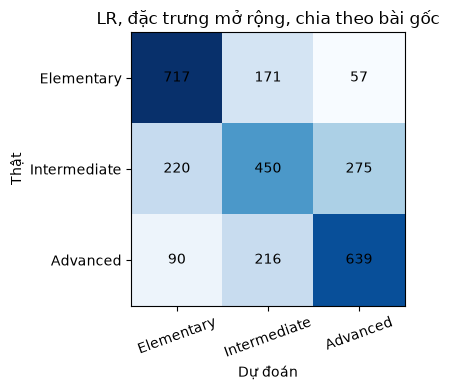

In [6]:
cm = matrices[('Mở rộng (10)', 'LR', 'group')]
names = list(ORDER)
print(pd.DataFrame(cm, index=[f'Thật: {n}' for n in names], columns=[f'Dự đoán: {n}' for n in names]))
print('Recall theo mức:', dict(zip(names, (cm.diagonal()/cm.sum(1)).round(3))))
print('Tỷ lệ nhầm Elementary ↔ Advanced:', round((cm[0,2]+cm[2,0])/cm.sum(), 3))
fig, ax = plt.subplots(figsize=(4.5,4))
ax.imshow(cm, cmap='Blues')
for i in range(3):
    for j in range(3): ax.text(j, i, cm[i,j], ha='center', va='center')
ax.set_xticks(range(3)); ax.set_xticklabels(names, rotation=20); ax.set_yticks(range(3)); ax.set_yticklabels(names)
ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thật'); ax.set_title('LR, đặc trưng mở rộng, chia theo bài gốc')
plt.tight_layout(); plt.show()

## 4. Đặc trưng nào phân biệt ba mức
Thống kê Kruskal-Wallis (H càng lớn càng phân biệt tốt) và trung bình theo mức.

In [7]:
rows = []
for c in EXP + ['fk']:
    g3 = [df.loc[df.level == l, c] for l in ORDER]
    rows.append(dict(feature=c, H=kruskal(*g3)[0], **{l[:4]: g.mean() for l, g in zip(ORDER, g3)}))
pd.DataFrame(rows).sort_values('H', ascending=False).round(3).reset_index(drop=True)

,feature,H,Elem,Inte,Adva
0,sent_len,206.155,16.643,19.560,21.875
1,fk,191.300,8.366,10.135,11.382
2,sub_per_sent,92.380,1.060,1.233,1.438
3,ratio_outside_top5k,80.430,0.076,0.094,0.103
4,p10_zipf,77.459,4.203,4.044,3.979
5,long_word_ratio,75.569,0.197,0.220,0.234
6,mean_zipf,70.103,5.826,5.750,5.733
7,word_len,53.247,4.541,4.652,4.730
8,rare_ratio,28.889,0.023,0.030,0.029
9,words_per_clause,11.922,6.411,6.676,6.619


## 5. Văn bản khó phân biệt nhất
Dự đoán out-of-fold bằng LR (đặc trưng mở rộng, chia theo bài gốc); liệt kê các văn bản bị đoán sai **hai mức** và các bài mà cả ba phiên bản bị nhầm nhiều nhất. Nhóm nên đọc trực tiếp các văn bản này.

In [8]:
X = df[EXP].values
oof = np.full(len(df), -1)
for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups):
    oof[te] = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(X[tr], y[tr]).predict(X[te])
df['pred'] = oof
df['pred_level'] = df.pred.map({v: k for k, v in ORDER.items()})
df['abs_err'] = np.abs(df.pred - y)
print('Accuracy out-of-fold:', round((df.pred == y).mean(), 3))
far = df[df.abs_err == 2][['article','level','pred_level','sent_len','sub_per_sent']]
print('Số văn bản bị nhầm hai mức:', len(far)); display(far.head(15))
hard = df.groupby('article').abs_err.sum().sort_values(ascending=False).head(10)
print('10 bài gốc có tổng lỗi lớn nhất (cộng ba phiên bản):'); display(hard)

Accuracy out-of-fold: 0.637
Số văn bản bị nhầm hai mức: 28


,article,level,pred_level,sent_len,sub_per_sent
1,Amsterdam,Elementary,Advanced,20.090909,1.636364
5,Billionaires,Elementary,Advanced,19.944444,1.555556
7,Bolivia,Elementary,Advanced,18.387097,1.387097
10,Cigarettes,Elementary,Advanced,20.782609,1.521739
39,Midlife crisis,Elementary,Advanced,19.083333,1.291667
69,WNL Bangladesh factory owners,Elementary,Advanced,21.217391,1.782609
75,WNL Bogus Allergy,Elementary,Advanced,18.925926,1.740741
99,WNL Glastonbury,Elementary,Advanced,16.190476,0.714286
106,WNL Icelandic names,Elementary,Advanced,18.160000,1.120000
149,WNL Ships noise,Elementary,Advanced,17.718750,1.312500


10 bài gốc có tổng lỗi lớn nhất (cộng ba phiên bản):


article
Amsterdam            3
Bolivia              3
Cigarettes           3
Billionaires         3
Fitness              3
Gangs                3
Japan                3
Norwegian sun        3
Midlife crisis       3
WNL Canadian Pair    3
Name: abs_err, dtype: int64

## 6. Kiểm tra thêm: mô hình TF-IDF
Mô hình dung lượng cao có thể học từ vựng chủ đề của từng bài. Kiểm tra xem hai cách chia cho kết quả ra sao với TF-IDF n-gram (1 đến 2) + LR, 3 lần lặp.
Kết quả lần chạy của nhóm: chia theo bài gốc ≈ 0,84 accuracy, chia ngẫu nhiên ≈ 0,34. **Kết quả này bất ngờ (đảo chiều so với giả thuyết rò rỉ); cần kiểm tra lại trước khi kết luận trong bài.**

In [9]:
texts = data.text.values
tfidf_res = {}
for kind in ['group', 'random']:
    acc, qwk = [], []
    for rep in range(3):
        for tr, te in splitter(kind, texts, rep):
            m = make_pipeline(TfidfVectorizer(ngram_range=(1,2), min_df=2, sublinear_tf=True),
                              LogisticRegression(C=30, max_iter=3000)).fit(texts[tr], y[tr])
            p = m.predict(texts[te])
            acc.append(accuracy_score(y[te], p)); qwk.append(cohen_kappa_score(y[te], p, weights='quadratic'))
    tfidf_res[kind] = (np.mean(acc), np.mean(qwk))
pd.DataFrame(tfidf_res, index=['accuracy','qwk']).T.round(3)

,accuracy,qwk
group,0.841,0.868
random,0.336,0.369


## 7. Thử trên văn bản ngoài bộ dữ liệu
Nhóm **tự chọn và điền** 5 văn bản (nguồn công khai, ghi rõ nguồn) vào `EXTERNAL_TEXTS`, kèm mức nhóm tự gán sau khi thảo luận. Mô hình trả về mức dự đoán và xác suất; xác suất giúp giáo viên thấy văn bản sát ranh giới.

In [10]:
final_model = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=2000)).fit(df[EXP].values, y)
inv = {v: k for k, v in ORDER.items()}

def predict_level(text):
    f = pd.DataFrame([extract(text)])[EXP].values
    proba = final_model.predict_proba(f)[0]
    return inv[int(proba.argmax())], dict(zip(inv.values(), proba.round(3)))

# Điền 5 văn bản: {'tên/nguồn': ('nội dung văn bản', 'mức nhóm gán hoặc None')}
EXTERNAL_TEXTS = {
    # 'Nguồn 1': ('...', 'Intermediate'),
}
if not EXTERNAL_TEXTS:
    print('Chưa có văn bản ngoài bộ dữ liệu. Điền vào EXTERNAL_TEXTS rồi chạy lại ô này.')
else:
    out = []
    for name, (txt, gold) in EXTERNAL_TEXTS.items():
        lvl, p = predict_level(txt); out.append(dict(source=name, group_label=gold, predicted=lvl, **p))
    display(pd.DataFrame(out))

Chưa có văn bản ngoài bộ dữ liệu. Điền vào EXTERNAL_TEXTS rồi chạy lại ô này.


## 8. Kết luận và giới hạn
- Mở rộng đặc trưng giúp LR tăng khoảng 4,7 điểm accuracy so với 3 đặc trưng gốc và khoảng 8,5 điểm so với Flesch-Kincaid (chia theo bài gốc).
- Với đặc trưng thủ công, hai cách chia chỉ chênh 0 đến 2 điểm; kết quả TF-IDF đảo chiều và cần kiểm tra lại.
- Intermediate là mức khó nhất; nhầm Elementary với Advanced chiếm khoảng 5% dự đoán.
- Giới hạn: chưa tune siêu tham số, chưa có khoảng tin cậy, số âm tiết và số mệnh đề là ước lượng, chưa có Academic Word List thật, chưa có văn bản ngoài bộ dữ liệu.
- Việc tiếp theo: tune siêu tham số, thay AWL thật, đọc các văn bản khó phân biệt nhất (mục 5), điền văn bản ngoài (mục 7), BERT-base tinh chỉnh (chia theo bài gốc) khi môn học tới phần này.
- Công cụ dùng như baseline: kết quả chỉ là gợi ý, giáo viên luôn là người quyết định.

**Tài liệu:** Vajjala, S. & Lučić, I. (2018), OneStopEnglish corpus; Lee và cộng sự (2021); Pan và cộng sự (2024/2025) – nhóm điền trích dẫn đầy đủ.